# A bank run: when events infect one another

*Beyond the scriptum — an application.*

---

The insurance company in `insurance_realistic` had claims that arrived **independently**. Even the
clusters (one accident, several parties) were only bigger packets — one packet knew nothing about the
next.

A bank run is different. People withdraw because **they see others withdrawing**. Every withdrawal
raises the probability of the next. This is called a **self-exciting process** (Hawkes, 1971), and it is
the last missing mechanism in the repository: **feedback in time**.

We write the model in a form that gives an exact check. Every withdrawal has two causes:

- **on its own** (an immigrant): people turn up in their own way, with intensity $\mu$,
- **contagion**: every withdrawal triggers $\operatorname{Poisson}(n)$ further withdrawals with a random
  delay.

The number $n$ is the **branching ratio** and it is exactly the $R_0$ from the notebook
`branching_process` — every withdrawal "infects" on average $n$ others. Everything follows from that:

$$\text{the mean size of a cluster} = \frac{1}{1-n}, \qquad \text{the total intensity} = \frac{\mu}{1-n},$$

and for $n \ge 1$ the process is **unstable** — the run does not stop on its own.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def poisson(lam):
    if lam > 60:
        return max(0, int(round(random.gauss(lam, math.sqrt(lam)))))
    L, p, k = math.exp(-lam), 1.0, 0
    while True:
        p *= random.random()
        if p < L:
            return k
        k += 1


def estimate(xs):
    n = len(xs)
    m = sum(xs) / n
    var = sum((x - m) ** 2 for x in xs) / (n - 1)
    return m, math.sqrt(var / n)

## 1. The size of an avalanche: an exact check

First we verify the theory. A single withdrawal sets off an avalanche: itself, its "offspring", their
offspring… That is **exactly the branching process** from `branching_process`, except that the
offspring do not appear in generations but spread out in time.

The mean size of the avalanche follows from a plain sum over the generations:

$$1 + n + n^2 + n^3 + \dots = \frac{1}{1-n} \qquad (n < 1).$$

In [2]:
def avalanche_size(n, cap=100_000):
    '''How many withdrawals in total one spontaneous withdrawal triggers (including itself).'''
    total, generation = 0, 1
    while generation > 0 and total < cap:
        total += generation
        generation = (poisson(generation * n) if generation >= 2000
                      else sum(poisson(n) for _ in range(generation)))
    return total


print(f"{'n':>5s} {'the mean size of an avalanche':>31s} {'exactly 1/(1-n)':>17s}")
for n in (0.0, 0.3, 0.5, 0.8, 0.9):
    vals = [avalanche_size(n) for _ in range(20_000)]
    m, se = estimate(vals)
    print(f"{n:>5.1f} {m:>18.3f} +- {se:.3f} {1 / (1 - n):>17.3f}")
    assert abs(m - 1 / (1 - n)) < 5 * se + 1e-9   # +eps: for n = 0 the variance is zero

print("\nAt n = 0.9 one withdrawal triggers on average ten more. And as we shall see,")
print("that average is treacherous: most avalanches are small, a few are enormous.")

    n   the mean size of an avalanche   exactly 1/(1-n)
  0.0              1.000 +- 0.000             1.000
  0.3              1.437 +- 0.007             1.429
  0.5              1.996 +- 0.014             2.000
  0.8              5.072 +- 0.072             5.000
  0.9             10.261 +- 0.215            10.000

At n = 0.9 one withdrawal triggers on average ten more. And as we shall see,
that average is treacherous: most avalanches are small, a few are enormous.


## 2. The phase transition and why it is dangerous

As in the branching process, the kink is at $n = 1$. Below it an avalanche always stops, above it it
need not. But there is something that makes runs so treacherous:

**Just below one the system looks calm, yet the avalanches already have an enormous variance.**

The mean size $1/(1-n)$ grows to infinity, but **the variance grows much faster**. A bank at
$n = 0.9$ sees perfectly normal operation on most days — and once in a while an avalanche a hundred
times larger than the average.

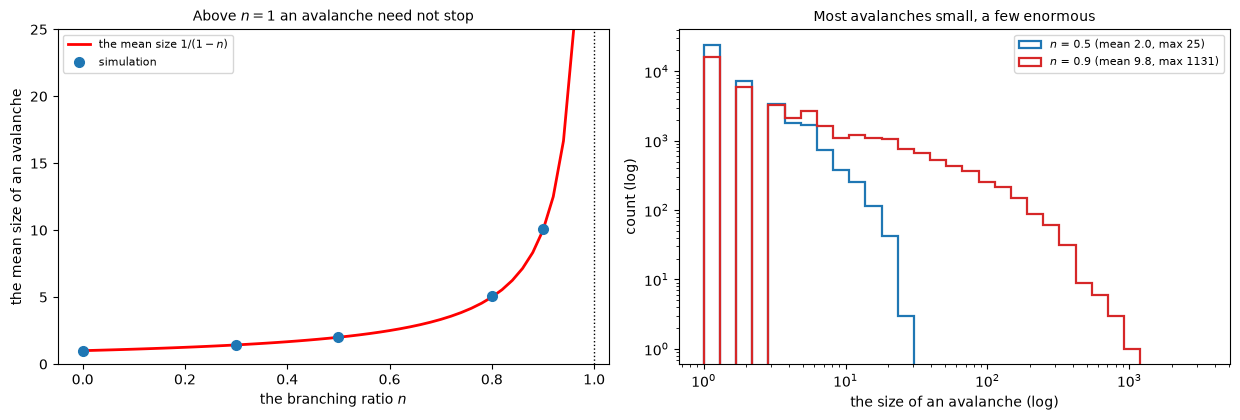

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
nn = [0.02 * i for i in range(50)]
ax.plot(nn, [1 / (1 - n) for n in nn], "r-", lw=2, label="the mean size $1/(1-n)$")
nn_sim = (0.0, 0.3, 0.5, 0.8, 0.9)
ax.plot(nn_sim, [estimate([avalanche_size(n) for _ in range(6000)])[0] for n in nn_sim],
        "o", ms=7, label="simulation")
ax.axvline(1.0, color="k", ls=":", lw=1)
ax.set_xlabel("the branching ratio $n$")
ax.set_ylabel("the mean size of an avalanche")
ax.set_ylim(0, 25)
ax.set_title("Above $n = 1$ an avalanche need not stop", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
for n, color in ((0.5, "tab:blue"), (0.9, "tab:red")):
    vals = [avalanche_size(n) for _ in range(40_000)]
    ax.hist(vals, bins=[1.3**i for i in range(0, 32)], histtype="step", lw=1.6,
            color=color, label=f"$n$ = {n} (mean {sum(vals) / len(vals):.1f}, max {max(vals)})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("the size of an avalanche (log)")
ax.set_ylabel("count (log)")
ax.set_title("Most avalanches small, a few enormous", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The right-hand plot is the essential one. At $n = 0.9$ **the median avalanche is still one** — the
overwhelming majority of withdrawals infect nobody. But the tail reaches into the hundreds. From
ordinary operation one therefore cannot tell how close to one the system is; it looks calm right up
until the moment it does not.

## 3. What it looks like in time

Now a process with real time: immigrants arrive with intensity $\mu$, and every withdrawal triggers
offspring with an exponential delay.

    n  withdrawals in total   exactly μT/(1-n)   of them spontaneous
  0.0        97.7 +-  1.6              100.0                  97.7
  0.5       204.7 +-  6.0              200.0                 101.7
  0.8       491.4 +- 15.6              500.0                  98.2
  0.9      1032.8 +- 47.8             1000.0                 101.8

(The simulation scatters around the formula within the standard error. A small downward effect is hidden in the
 noise: offspring that would arrive after time T are not counted, and the larger n, the more of them are cut off.)


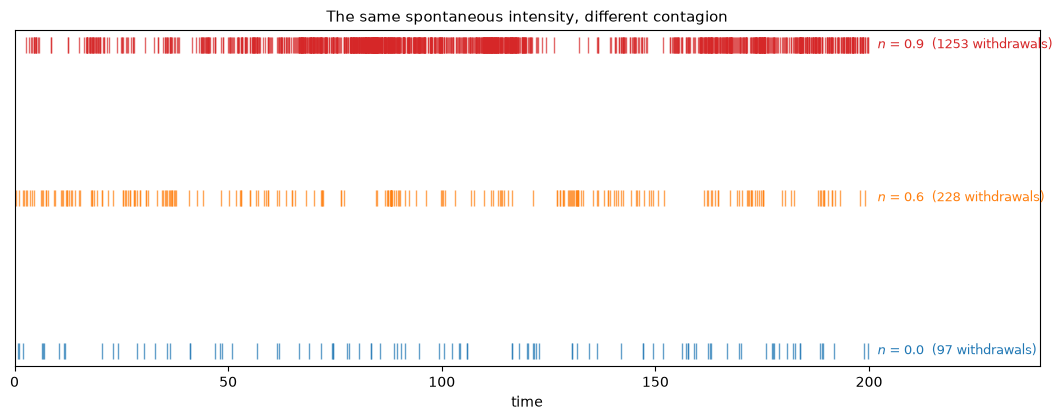

From top to bottom the clustering grows. The number of spontaneous withdrawals is the same in every row —
what differs is only how many each of them triggers. At n = 0.9 the withdrawals merge
into clusters that look like panic from afar, even though the model has not changed.


In [4]:
def simulate_in_time(mu, n, T, mean_delay=1.0, cap=200_000):
    '''A Hawkes process via immigration and branching. Returns the times of all withdrawals.'''
    times = []
    # spontaneous arrivals: a Poisson process of intensity mu
    t = 0.0
    seeds = []
    while True:
        t += random.expovariate(mu)
        if t > T:
            break
        seeds.append(t)
    queue = list(seeds)
    while queue and len(times) < cap:
        t0 = queue.pop()
        times.append(t0)
        for _ in range(poisson(n)):
            t1 = t0 + random.expovariate(1 / mean_delay)
            if t1 <= T:
                queue.append(t1)
    return sorted(times), len(seeds)


MU, T = 0.5, 200.0
print(f"{'n':>5s} {'withdrawals in total':>21s} {'exactly μT/(1-n)':>18s} {'of them spontaneous':>21s}")
for n in (0.0, 0.5, 0.8, 0.9):
    total, spont = [], []
    for _ in range(30):
        c, z = simulate_in_time(MU, n, T)
        total.append(len(c)); spont.append(z)
    m, se = estimate(total)
    print(f"{n:>5.1f} {m:>11.1f} +- {se:>4.1f} {MU * T / (1 - n):>18.1f} {sum(spont) / len(spont):>21.1f}")

print("\n(The simulation scatters around the formula within the standard error. A small downward effect is hidden in the")
print(" noise: offspring that would arrive after time T are not counted, and the larger n, the more of them are cut off.)")

fig, ax = plt.subplots(figsize=(11, 4.3))
for i, (n, color) in enumerate(((0.0, "tab:blue"), (0.6, "tab:orange"), (0.9, "tab:red"))):
    times, _ = simulate_in_time(MU, n, T)
    ax.plot(times, [i] * len(times), "|", ms=12, color=color, alpha=0.7)
    ax.text(T * 1.01, i, f"$n$ = {n}  ({len(times)} withdrawals)", va="center", fontsize=9, color=color)
ax.set_yticks([])
ax.set_xlim(0, T * 1.2)
ax.set_xlabel("time")
ax.set_title("The same spontaneous intensity, different contagion", fontsize=11)
plt.tight_layout()
plt.show()

print("From top to bottom the clustering grows. The number of spontaneous withdrawals is the same in every row —")
print("what differs is only how many each of them triggers. At n = 0.9 the withdrawals merge")
print("into clusters that look like panic from afar, even though the model has not changed.")

## 4. What follows from it

Three things this model says that are not obvious:

**Clusters need no cause.** The last picture looks as though at certain moments "news arrived" and
people started to panic. It did not. The model is the same throughout and the intensity of the
immigrants is constant — the clusters were made by the feedback alone. **Looking for an external cause
for every cluster is a mistake.**

**Ordinary operation does not reveal how close to the edge you are.** The median avalanche is 1 even at
$n = 0.9$. The difference between a safe and a dangerous system shows only in the tail, i.e. in data
that you almost never have.

**An intervention has to aim at $n$, not at $\mu$.** Reducing the spontaneous withdrawals (a
reassuring announcement, say) reduces the total number proportionally. But cutting the contagion $n$
from 0.9 to 0.8 halves the avalanches — and so does going from 0.95 to 0.9. Near one every little step
has an enormous leverage, exactly like $R_0$ in an epidemic.

In [5]:
print("What helps more: reducing the spontaneous withdrawals, or the contagion?\n")
MU0, N0 = 0.5, 0.9
baseline = MU0 * T / (1 - N0)
print(f"the initial state: μ = {MU0}, n = {N0}  ->  the expected number of withdrawals {baseline:.0f}")
print(f"\n{'intervention':>40s} {'withdrawals':>12s} {'change':>9s}")
for label, mu_, n_ in (("reduce μ by 20 % (calm the public)", MU0 * 0.8, N0),
                       ("reduce n by 20 % (slow the contagion)", MU0, N0 * 0.8),
                       ("both by 10 %", MU0 * 0.9, N0 * 0.9)):
    ec = mu_ * T / (1 - n_)
    print(f"{label:>40s} {ec:>12.0f} {ec / baseline - 1:>8.0%}")

print("\nReducing the contagion is incomparably more effective for a system near the boundary —")
print("μ enters the formula linearly, whereas n enters through 1/(1-n).")

What helps more: reducing the spontaneous withdrawals, or the contagion?

the initial state: μ = 0.5, n = 0.9  ->  the expected number of withdrawals 1000

                            intervention  withdrawals    change
      reduce μ by 20 % (calm the public)          800     -20%
   reduce n by 20 % (slow the contagion)          357     -64%
                            both by 10 %          474     -53%

Reducing the contagion is incomparably more effective for a system near the boundary —
μ enters the formula linearly, whereas n enters through 1/(1-n).


## Summary

| Concept | What to remember |
|---------|------------------|
| A self-exciting process | every event raises the intensity of the next (Hawkes) |
| The branching ratio $n$ | the mean number of events triggered by one event — the same as $R_0$ |
| The size of an avalanche | exactly $1/(1-n)$; it is the sum of the generations $1 + n + n^2 + \dots$ |
| The total intensity | $\mu/(1-n)$ — the spontaneous withdrawals amplified by contagion |
| Stability | $n < 1$ stops, $n \ge 1$ need not |
| The treachery | the median avalanche is 1 even at $n = 0.9$; the danger shows only in the tail |
| Clusters with no cause | feedback creates clusters without any external event |
| Where to intervene | on $n$, not on $\mu$ — $n$ acts through $1/(1-n)$ |

This closes the repository: `branching_process` had feedback in generations, this notebook has it in
time, and `percolation` has the same phase transition in space. All three have a kink at a single
point, and in all three the system looks fine just below it.

### Try it yourself

1. Verify the formula for the **variance** of the avalanche size, $\dfrac{n}{(1-n)^3}$ (for Poisson
   offspring). Does it confirm that it grows much faster than the mean?
2. Replace the exponential delay by a **power-law** one (a long memory, like the aftershocks of an
   earthquake). Does the size of the avalanches change, or only their distribution in time?
3. Give the bank a **reserve**: it goes bust when the number of withdrawals per day exceeds a
   threshold. Compute the probability of failure as a function of $n$.
4. Estimate $n$ from the observed data (from the withdrawal times alone, without knowing who infected
   whom). How accurately can it be done?
5. Introduce an intervention: when a threshold is exceeded, $n$ is halved (the bank limits
   withdrawals). How much does it help and how early must the intervention come?
6. Compare the distribution of the avalanche size at $n = 0.99$ with a power law. Does it approach it?
   (For a critical branching process the exponent is $-3/2$.)